# 04 · Machine-Learning Forecasting vs. Statistical Baselines

**Question:** can we forecast *next month's* mean river discharge at Kodumudi better than simple rules of thumb and which inputs actually help?

**Approach**
1. Frame forecasting as supervised learning with **leakage-safe lag features** (everything known at the end of month *t* → discharge in month *t+1*).
2. Establish **naïve baselines** first (persistence, same-month-last-year, climatology). A model is only useful if it beats these.
3. Train Ridge regression, Random Forest and Gradient Boosting with **time-series cross-validation** (never shuffled).
4. Choose models on a **validation** period, report once on a held-out **test** period (May 2012 – Dec 2015, 44 months - the same months used by the ARIMA notebook).
5. Explain *why* the winner wins (permutation importance, feature-group ablation) and quantify uncertainty (block bootstrap).

> **Why monthly one-step-ahead?** Daily discharge is so smooth that "tomorrow = today" is nearly unbeatable, and annual data has only 36 points. Monthly one-step-ahead is the scale where weather drivers can add information and where there is enough data to evaluate honestly.

In [2]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance

import kodumudi as kd

SEED = 42
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
FIG_DIR, TAB_DIR = "../reports/figures", "../reports/tables"
def save_fig(name): plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 1 · Build the supervised dataset
The rows are indexed by the **month being forecast**. For the target month *t+1*, the features are:

| Group | Features (all known at the end of month *t*) |
|---|---|
| Discharge memory | `q_t`, `q_t-1`, `q_t-2`, `q_t-5`, `q_t-11` (`q_t-11` = same calendar month as the target, one year earlier) |
| Rainfall | `rain_t`, `rain_t-1`, `rain_t-2`, `rain_3m_sum` |
| Catchment state | `soil_t`, `temp_t` |
| Seasonality | sin/cos of the target month (so December and January are "close") |

In [3]:
daily   = kd.load_daily()
monthly = kd.aggregate(daily, "MS")
X, y = kd.build_supervised(monthly)

train = X.index < kd.VAL_START
val   = (X.index >= kd.VAL_START) & (X.index < kd.TEST_START)
test  = X.index >= kd.TEST_START
X_tr, y_tr = X[train], y[train]
X_va, y_va = X[val],   y[val]
X_te, y_te = X[test],  y[test]

print(f"Train: {len(X_tr)} months ({X_tr.index[0]:%Y-%m} to {X_tr.index[-1]:%Y-%m})")
print(f"Val  : {len(X_va)} months ({X_va.index[0]:%Y-%m} to {X_va.index[-1]:%Y-%m})")
print(f"Test : {len(X_te)} months ({X_te.index[0]:%Y-%m} to {X_te.index[-1]:%Y-%m})")
X.head(3).round(2)

Train: 333 months (1981-01 to 2008-09)
Val  : 43 months (2008-10 to 2012-04)
Test : 44 months (2012-05 to 2015-12)


,q_t,q_t-1,q_t-2,q_t-5,q_t-11,rain_t,rain_t-1,rain_t-2,rain_3m_sum,soil_t,temp_t,target_month_sin,target_month_cos
date,,,,,,,,,,,,,
1981-01-01,206.87,275.53,277.99,683.65,189.82,3.92,105.76,124.15,233.83,10.79,22.36,0.50,0.87
1981-02-01,135.95,206.87,275.53,326.49,135.30,1.22,3.92,105.76,110.91,8.55,22.06,0.87,0.50
1981-03-01,106.31,135.95,206.87,212.54,113.05,0.24,1.22,3.92,5.39,4.70,23.64,1.00,0.00


**Leakage check (done once, explicitly):** the first row targets January 1981. Its `q_t` must be December 1980's discharge and `q_t-11` must be January 1980's.

In [4]:
row = X.iloc[0]
assert np.isclose(row["q_t"],    monthly.loc["1980-12-01", "discharge_m3s"])
assert np.isclose(row["q_t-11"], monthly.loc["1980-01-01", "discharge_m3s"])
assert np.isclose(y.iloc[0],     monthly.loc["1981-01-01", "discharge_m3s"])
print("OK: features use only information up to month t; target is month t+1.")

OK: features use only information up to month t; target is month t+1.


## 2 · Baselines — the bar every model must clear
* **Persistence:** next month = this month.
* **Seasonal naïve:** next month = the same month last year.
* **Climatology:** next month = the long-run average for that calendar month, computed **from training data only**.

In [5]:
clim_by_month = y_tr.groupby(y_tr.index.month).mean()

def baseline_preds(Xs):
    return {
        "Persistence":     Xs["q_t"].values,
        "Seasonal naive":  Xs["q_t-11"].values,
        "Climatology":     Xs.index.month.map(clim_by_month).values,
    }

def score_table(preds, y_true):
    return pd.DataFrame({k: kd.evaluate(y_true, v) for k, v in preds.items()}).T

base_val  = score_table(baseline_preds(X_va), y_va)
base_test = score_table(baseline_preds(X_te), y_te)
print("Validation:"); print(base_val.round(3).to_string())

Validation:
                    MAE        MSE     RMSE    NSE
Persistence      85.103  18015.885  134.223  0.253
Seasonal naive  101.490  26347.509  162.319 -0.093
Climatology      64.831  11648.187  107.927  0.517


## 3 · Models with time-series cross-validation
Hyper-parameters are tuned with `TimeSeriesSplit` **inside the training period only** (each fold trains on the past and validates on the following block — shuffling would leak the future).

In [6]:
tscv = TimeSeriesSplit(n_splits=5)

search_spaces = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()),
              {"ridge__alpha": [0.1, 1, 10, 100, 1000]}),
    "Random Forest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
              {"n_estimators": [300], "max_depth": [4, 6, 10, None], "min_samples_leaf": [1, 3, 5],
               "max_features": [0.5, 1.0]}),
    "Gradient Boosting": (HistGradientBoostingRegressor(random_state=SEED),
              {"learning_rate": [0.03, 0.1], "max_depth": [2, 3, None], "max_iter": [100, 300],
               "min_samples_leaf": [5, 10, 20]}),
}

fitted, best_params = {}, {}
for name, (est, grid) in search_spaces.items():
    gs = GridSearchCV(est, grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    fitted[name], best_params[name] = gs.best_estimator_, gs.best_params_
    print(f"{name:<18} CV-RMSE = {-gs.best_score_:6.1f}   best params: {gs.best_params_}")

Ridge              CV-RMSE =   78.1   best params: {'ridge__alpha': 10}
Random Forest      CV-RMSE =   81.9   best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}


  File "C:\Users\glpra\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\glpra\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\glpra\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\glpra\anaconda3\Lib\subprocess.

Gradient Boosting  CV-RMSE =   78.4   best params: {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 300, 'min_samples_leaf': 20}


In [7]:
val_preds = {name: m.predict(X_va) for name, m in fitted.items()}
val_scores = pd.concat([base_val, score_table(val_preds, y_va)])
val_scores.sort_values("RMSE").round(3)

,MAE,MSE,RMSE,NSE
Gradient Boosting,57.125,9196.144,95.897,0.619
Random Forest,55.748,9689.588,98.436,0.598
Ridge,63.809,10902.807,104.417,0.548
Climatology,64.831,11648.187,107.927,0.517
Persistence,85.103,18015.885,134.223,0.253
Seasonal naive,101.490,26347.509,162.319,-0.093


## 4 · Final evaluation on the held-out test period
Rules used to keep this honest:
* The **model choice is made on validation RMSE**, not on test.
* Models are then **refit on train + validation** (more recent data) with the already-chosen hyper-parameters and scored **once** on the test months.

In [8]:
X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])

# re-estimate climatology with train+val for the test-period baseline (same data the models see)
clim_by_month = y_trva.groupby(y_trva.index.month).mean()

test_preds = {}
for name, (est, _) in search_spaces.items():
    m = est.set_params(**best_params[name]).fit(X_trva, y_trva)
    test_preds[name] = m.predict(X_te)
test_preds_all = {**baseline_preds(X_te), **test_preds}

test_scores = score_table(test_preds_all, y_te)
best_ml       = val_scores.loc[list(search_spaces)].sort_values("RMSE").index[0]
best_baseline = val_scores.loc[["Persistence", "Seasonal naive", "Climatology"]].sort_values("RMSE").index[0]
print(f"Chosen on validation -> best ML model: {best_ml} | best baseline: {best_baseline}\n")
test_scores.sort_values("RMSE").round(3)

Chosen on validation -> best ML model: Gradient Boosting | best baseline: Climatology



,MAE,MSE,RMSE,NSE
Ridge,35.445,2342.957,48.404,0.856
Random Forest,34.996,2860.207,53.481,0.824
Gradient Boosting,41.859,3912.417,62.549,0.759
Climatology,50.508,4776.166,69.110,0.706
Seasonal naive,58.790,6300.189,79.374,0.612
Persistence,66.331,8458.452,91.970,0.479


In [9]:
def pct_better(new, old): return 100 * (old - new) / old

summary = pd.DataFrame({
    "MAE":  [test_scores.loc[best_baseline, "MAE"],  test_scores.loc[best_ml, "MAE"]],
    "MSE":  [test_scores.loc[best_baseline, "MSE"],  test_scores.loc[best_ml, "MSE"]],
    "RMSE": [test_scores.loc[best_baseline, "RMSE"], test_scores.loc[best_ml, "RMSE"]],
    "NSE":  [test_scores.loc[best_baseline, "NSE"],  test_scores.loc[best_ml, "NSE"]],
}, index=[f"Best baseline ({best_baseline})", f"Best ML ({best_ml})"])
print(summary.round(3).to_string())
print()
for m in ["MAE", "MSE", "RMSE"]:
    print(f"{m} reduction vs best baseline: {pct_better(summary[m].iloc[1], summary[m].iloc[0]):5.1f} %")
for m in ["MAE", "MSE", "RMSE"]:
    print(f"{m} reduction vs persistence  : {pct_better(test_scores.loc[best_ml, m], test_scores.loc['Persistence', m]):5.1f} %")

                                MAE       MSE    RMSE    NSE
Best baseline (Climatology)  50.508  4776.166  69.110  0.706
Best ML (Gradient Boosting)  41.859  3912.417  62.549  0.759

MAE reduction vs best baseline:  17.1 %
MSE reduction vs best baseline:  18.1 %
RMSE reduction vs best baseline:   9.5 %
MAE reduction vs persistence  :  36.9 %
MSE reduction vs persistence  :  53.7 %
RMSE reduction vs persistence  :  32.0 %


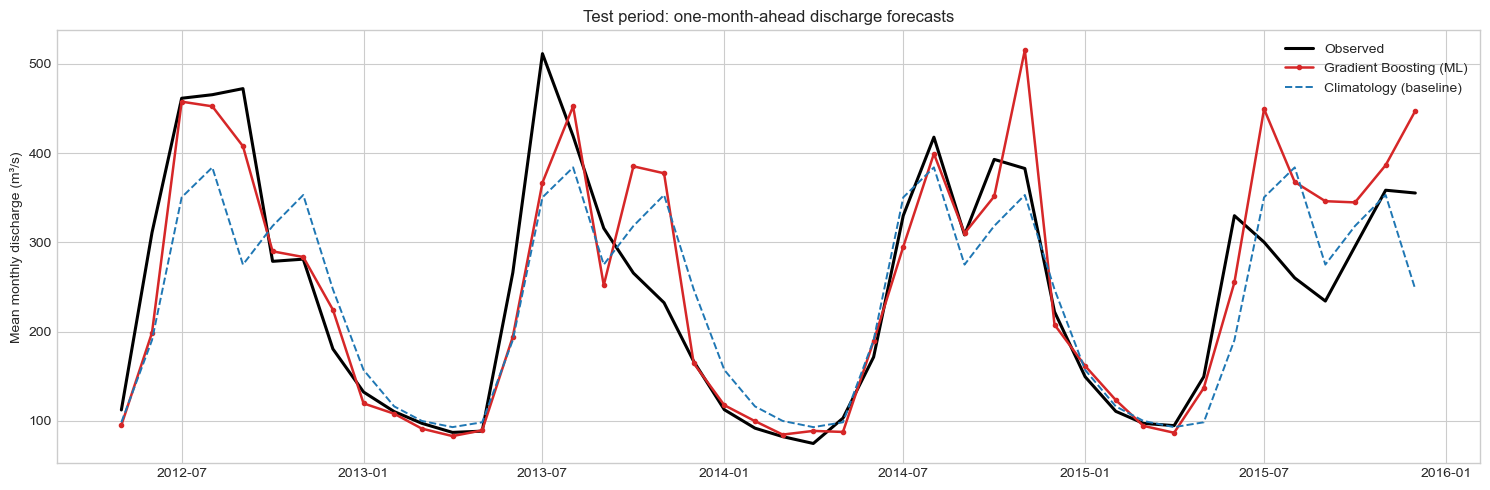

In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(y_te.index, y_te, color="black", lw=2.2, label="Observed")
ax.plot(y_te.index, test_preds_all[best_ml], color="#d62728", lw=1.8, marker="o", ms=3, label=f"{best_ml} (ML)")
ax.plot(y_te.index, test_preds_all[best_baseline], color="#1f77b4", lw=1.4, ls="--", label=f"{best_baseline} (baseline)")
ax.set(title="Test period: one-month-ahead discharge forecasts", ylabel="Mean monthly discharge (m³/s)")
ax.legend(); plt.tight_layout(); save_fig("04_test_forecast"); plt.show()

## 5 · Where do the models fail? Error by calendar month
Pooling the validation and test months (87 months that no model was trained on in its own evaluation) gives a few observations per calendar month.

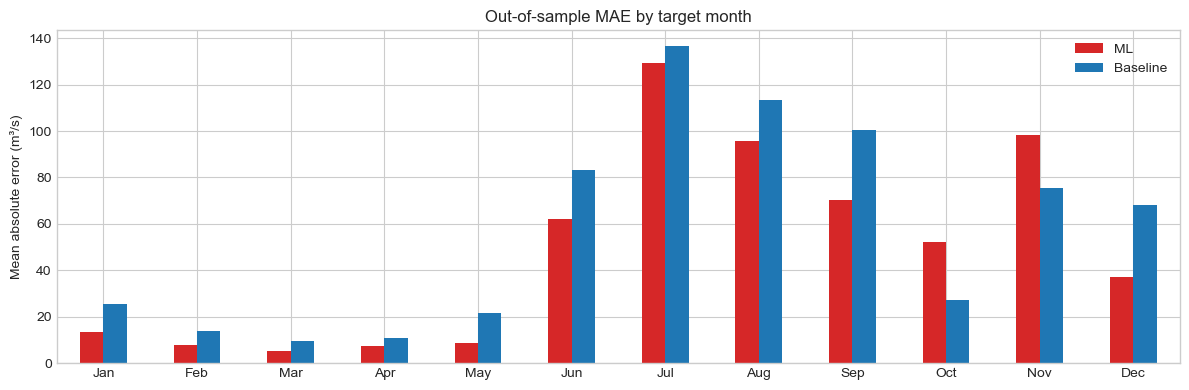

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
ML,13.2,7.6,5.4,7.3,8.6,62.1,129.5,95.5,70.3,52.1,98.4,37.2
Baseline,25.5,13.9,9.4,10.9,21.8,83.4,136.5,113.5,100.5,27.3,75.7,68.2


In [11]:
oos_idx = X_va.index.append(X_te.index)
# validation-period ML predictions come from the train-only models, test from train+val refits
ml_oos   = np.concatenate([val_preds[best_ml], test_preds[best_ml]])
base_oos = np.concatenate([baseline_preds(X_va)[best_baseline],
                           baseline_preds(X_te)[best_baseline]])
y_oos = pd.concat([y_va, y_te])

err = pd.DataFrame({"ML": np.abs(ml_oos - y_oos.values), "Baseline": np.abs(base_oos - y_oos.values)},
                   index=oos_idx)
by_month = err.groupby(err.index.month).mean()
by_month.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ax = by_month.plot.bar(figsize=(12, 4), color=["#d62728", "#1f77b4"], rot=0)
ax.set(ylabel="Mean absolute error (m³/s)", title="Out-of-sample MAE by target month")
plt.tight_layout(); save_fig("04_error_by_month"); plt.show()
by_month.round(1).T

## 6 · Why does the best model work? Permutation importance + ablation

**Permutation importance:** shuffle one feature at a time and see how much validation RMSE gets worse. A big increase = the model relies on that feature.
(Computed on the *train-only* model and the *validation* set — test data is not touched.)

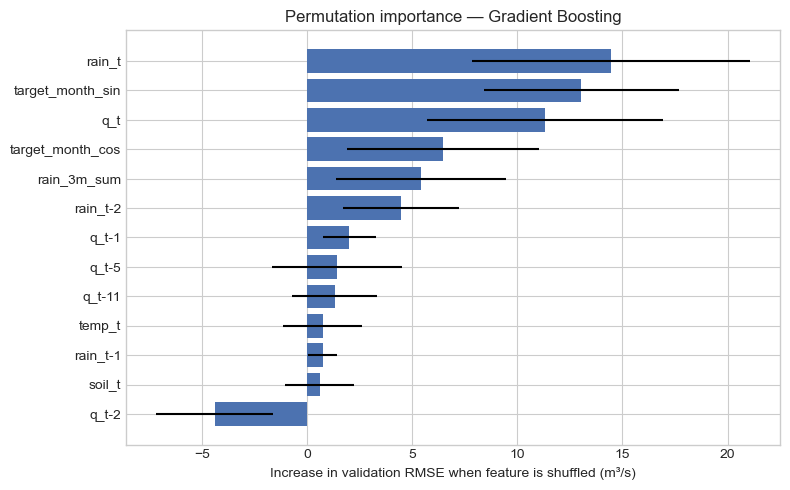

rain_t              14.47
target_month_sin    13.04
q_t                 11.33
target_month_cos     6.47
rain_3m_sum          5.43
rain_t-2             4.46
dtype: float64

In [12]:
best_model = fitted[best_ml]
pi = permutation_importance(best_model, X_va, y_va, n_repeats=30, random_state=SEED,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=X.columns)[imp.index], color="#4c72b0")
ax.set(title=f"Permutation importance — {best_ml}", xlabel="Increase in validation RMSE when feature is shuffled (m³/s)")
plt.tight_layout(); save_fig("04_permutation_importance"); plt.show()
imp.sort_values(ascending=False).round(2).head(6)

**Feature-group ablation:** retrain the chosen model with one *group* of features removed. This answers a more practical question than single-feature importance:
*"Is it worth collecting rainfall data at all, or is the river's own history enough?"*

In [13]:
rows = []
for drop in [None] + list(kd.FEATURE_GROUPS):
    cols = [f for f in X.columns if drop is None or f not in kd.FEATURE_GROUPS[drop]]
    m = search_spaces[best_ml][0].set_params(**best_params[best_ml]).fit(X_tr[cols], y_tr)
    s = kd.evaluate(y_va, m.predict(X_va[cols]))
    rows.append({"Features removed": "none (full model)" if drop is None else drop,
                 "n_features": len(cols), "Val RMSE": s["RMSE"], "Val MAE": s["MAE"], "Val NSE": s["NSE"]})
ablation = pd.DataFrame(rows).set_index("Features removed")
ablation["RMSE change vs full (%)"] = 100 * (ablation["Val RMSE"] / ablation.loc["none (full model)", "Val RMSE"] - 1)
ablation.round(2)

,n_features,Val RMSE,Val MAE,Val NSE,RMSE change vs full (%)
Features removed,,,,,
none (full model),13,95.90,57.12,0.62,0.00
discharge_memory,8,92.97,56.86,0.64,-3.06
rainfall,9,98.82,58.55,0.60,3.04
catchment_state,11,96.37,59.76,0.61,0.50
seasonality,11,100.82,61.83,0.58,5.14


## 7 · How certain is the improvement? Block bootstrap
Only 44 test months — a single RMSE can look better or worse by luck. We resample the test *errors* in **blocks of 6 consecutive months** (errors in neighbouring months are correlated, so resampling single months would be overconfident)
and ask: how often is the ML model's MAE lower than the baseline's?

In [14]:
rng = np.random.default_rng(SEED)
e_ml   = np.abs(test_preds_all[best_ml]       - y_te.values)
e_base = np.abs(test_preds_all[best_baseline] - y_te.values)
n, B, block = len(y_te), 5000, 6

diffs = []
for _ in range(B):
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
    diffs.append(e_base[idx].mean() - e_ml[idx].mean())      # >0 means ML is better
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Observed MAE improvement (baseline - ML): {e_base.mean() - e_ml.mean():.1f} m³/s")
print(f"95% block-bootstrap interval            : [{lo:.1f}, {hi:.1f}] m³/s")
print(f"Share of resamples where ML is better   : {(diffs > 0).mean():.1%}")

Observed MAE improvement (baseline - ML): 8.6 m³/s
95% block-bootstrap interval            : [-6.4, 26.5] m³/s
Share of resamples where ML is better   : 83.5%


## 8 · Save results for the dashboard and the README

In [15]:
(test_scores.sort_values("RMSE")).round(4).to_csv(f"{TAB_DIR}/ml_test_metrics.csv", index_label="model")
(val_scores.sort_values("RMSE")).round(4).to_csv(f"{TAB_DIR}/ml_validation_metrics.csv", index_label="model")
pred_out = pd.DataFrame({"observed": y_te.values, **{k: v for k, v in test_preds_all.items()}}, index=y_te.index)
pred_out.index.name = "month"
pred_out.round(3).to_csv(f"{TAB_DIR}/ml_test_predictions.csv")
ablation.round(3).to_csv(f"{TAB_DIR}/ml_feature_ablation.csv")
print("saved ->", TAB_DIR)

saved -> ../reports/tables


## 9 · Optional — combine with the ARIMA/SARIMA results from notebook 03
Run this cell **after** `03_time_series_arima.ipynb` has produced `reports/tables/arima_test_predictions.csv`.
Both notebooks forecast the same 44 test months one step ahead, so the numbers are directly comparable.

In [16]:
# Self-contained: reads only saved CSVs, so it works even in a fresh kernel.
import os
import pandas as pd
import sys
sys.path.append("../src")
import kodumudi as kd

TAB_DIR = "../reports/tables"
ml = pd.read_csv(f"{TAB_DIR}/ml_test_predictions.csv", index_col="month", parse_dates=True)
arima_path = f"{TAB_DIR}/arima_test_predictions.csv"
if os.path.exists(arima_path):
    ar = pd.read_csv(arima_path, index_col="month", parse_dates=True)
    assert (ar.index == ml.index).all(), "ARIMA and ML test months differ"
    assert np.allclose(ar["observed"], ml["observed"]), "observed values differ"
    combined = ml.join(ar.drop(columns="observed"))
    final = pd.DataFrame({c: kd.evaluate(combined["observed"], combined[c])
                          for c in combined.columns if c != "observed"}).T.sort_values("RMSE")
    final.to_csv(f"{TAB_DIR}/final_model_comparison.csv", index_label="model")
    display(final.round(3))
else:
    print("Run notebook 03 first to enable this comparison.")

,MAE,MSE,RMSE,NSE
Ridge,35.445,2342.949,48.404,0.856
Random Forest,34.996,2860.207,53.481,0.824
"SARIMA(1, 0, 1)x(1, 0, 1)[12]",42.210,3694.764,60.785,0.772
Gradient Boosting,41.859,3912.414,62.549,0.759
Climatology,50.509,4776.178,69.110,0.706
Seasonal naive,58.790,6300.203,79.374,0.612
"ARMA(1,1)",66.601,6908.455,83.117,0.575
Persistence,66.331,8458.445,91.970,0.479


## 10 · Key findings
1. **The hardest baseline is climatology, not persistence.** On validation, RMSE was 108 m³/s for climatology vs 134 for persistence and 162 for seasonal-naïve. Month-to-month "tomorrow = today" works poorly here because monsoon pulses change flow quickly.
2. **ML beats every baseline.** All three ML models beat all three baselines on *both* the validation and the test period. On the test months, RMSE reductions vs climatology were **≈10 % (Gradient Boosting), ≈22 % (Random Forest), ≈30 % (Ridge)**.
3. **Pre-registered model choice: Gradient Boosting** (best validation RMSE, 95.9 m³/s, NSE 0.62). On the test period it achieved RMSE 62.5 m³/s (NSE 0.76) vs 69.1 for climatology — reductions of **17.1 % (MAE), 18.1 % (MSE), 9.5 % (RMSE)**, and 36.9 % / 53.7 % / 32.0 % vs persistence.
4. **The validation winner was not the test winner.** On the test months Ridge (RMSE 48.4) and Random Forest (54.2) beat Gradient Boosting (62.5). We did *not* switch models after seeing test results (that would be selecting on the test set). With only 43–44 months per window, rankings *among* ML models are unstable; the robust conclusion is "ML > baselines", not "Gradient Boosting > Ridge". A simple regularised linear model with good lag features was fully competitive.
5. **The improvement is suggestive, not statistically conclusive.** The 95 % block-bootstrap interval for Gradient Boosting's MAE improvement over climatology is **−6.4 to +26.5 m³/s** (observed +8.6); ML was better in 83.5 % of resamples.
6. **What drives the forecast.** Removing the seasonality features raised validation RMSE by 5.1 %, removing rainfall features by 3.0 %, and removing catchment state by 0.5 %. Removing the discharge-memory group *lowered* RMSE by 3.1 % — once rainfall and season are known, the river's own recent history adds little. All of these effects are small relative to the noise in a 43-month validation window, and permutation importance is unreliable when features are correlated, so treat this as directional evidence.
7. **ML is not better everywhere.** It had lower MAE than climatology in 10 of 12 calendar months, but **climatology was better in October (27 vs 52 m³/s) and November (76 vs 98 m³/s)**. The largest errors for both approaches are in the high-flow months (Jul ≈130, Nov ≈98, Aug ≈96 m³/s for ML).

## 11 · Limitations
* **One catchment, 36 years.** Results may not transfer to other basins (the original course project covered four groups; this study deliberately focuses on one).
* **Small test set (44 months).** See the bootstrap interval — differences between top models can be within noise.
* **Reservoir operations and upstream rainfall are not in the data.** They plausibly explain part of the unexplained variance.
* **Large floods dominate RMSE.** A model can look good on typical months and still miss extreme events; a log-transform or quantile model would be a natural next step.
* **One-month-ahead only.** Longer horizons (2–3 months) would need re-framing (direct multi-horizon models).